# Brownian Motion and Langevin Dynamics

**References:** `Notes/lec_sde.pdf`, `Notes/Quiz2/07_Fokker_Planck_and_Langevin.ipynb`

## Concept & Formulas
Brownian particle moving in a fluid experiences viscous drag and random thermal kicks:
$$m\frac{dv}{dt} = -\gamma v + \xi(t)$$

- **Gaussian White Noise $\xi(t)$:** $\langle \xi(t) \rangle = 0$ and $\langle \xi(t)\xi(t') \rangle = 2\gamma k_B T\, \delta(t - t')$.
- **Euler-Maruyama Update (important $\sqrt{\Delta t}$ scaling!):**
  $$v_{n+1} = v_n - \frac{\gamma}{m} v_n \Delta t + \sqrt{\frac{2\gamma k_B T \Delta t}{m^2}}\,\eta_n, \qquad x_{n+1} = x_n + v_n \Delta t$$
  where $\eta_n \sim \mathcal{N}(0, 1)$ (`np.random.randn()`).
- **Overdamped Brownian Limit ($m$ small) & Einstein Relation:**
  $D = \frac{k_B T}{\gamma}$, $x_{n+1} = x_n + \sqrt{2D\Delta t}\,\eta_n$, giving $\langle x^2(t) \rangle = 2Dt$.
- **Limitations:** Random noise must scale as $\sqrt{\Delta t}$ (not $\Delta t$), and $\Delta t$ must be smaller than $m/\gamma$.

*Professor code: None provided separately for Langevin (uses the Quiz 2 Reference code).*

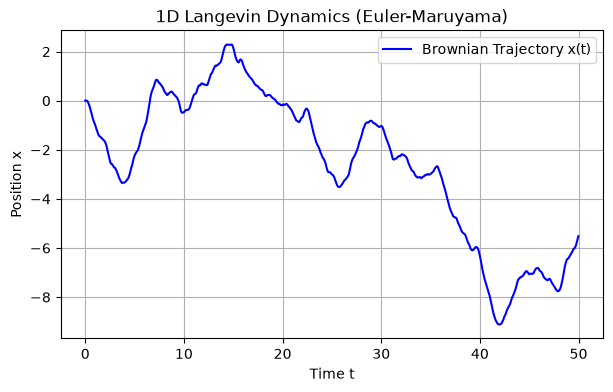

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Single 1D Langevin trajectory (Quiz 2 Reference Code)
m = 1.0
gamma = 1.0
kB_T = 1.0
dt = 0.01
t_end = 50.0
nt = int(t_end / dt)
noise_std = np.sqrt(2 * gamma * kB_T * dt / (m**2))

v = np.zeros(nt)
x = np.zeros(nt)
for i in range(nt - 1):
    v[i+1] = v[i] - (gamma / m) * v[i] * dt + noise_std * np.random.randn()
    x[i+1] = x[i] + v[i] * dt

t = np.arange(nt) * dt
plt.figure(figsize=(7, 4))
plt.plot(t, x, 'b-', label='Brownian Trajectory x(t)')
plt.xlabel('Time t'); plt.ylabel('Position x')
plt.title('1D Langevin Dynamics (Euler-Maruyama)')
plt.legend(); plt.grid(True)
plt.show()

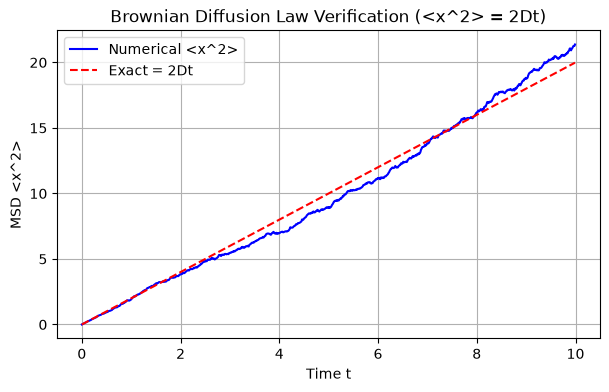

In [2]:
# Ensemble check: Overdamped Brownian motion MSD = 2*D*t (with D = kB*T / gamma)
D = kB_T / gamma
Nre = 500
nt_short = 1000
dt = 0.01
t_s = np.arange(nt_short) * dt

x_all = np.zeros((nt_short, Nre))
for ire in range(Nre):
    for i in range(nt_short - 1):
        x_all[i+1, ire] = x_all[i, ire] + np.sqrt(2 * D * dt) * np.random.randn()

msd_brownian = np.mean(x_all**2, axis=1)

plt.figure(figsize=(7, 4))
plt.plot(t_s, msd_brownian, 'b-', label='Numerical <x^2>')
plt.plot(t_s, 2 * D * t_s, 'r--', label='Exact = 2Dt')
plt.xlabel('Time t'); plt.ylabel('MSD <x^2>')
plt.title('Brownian Diffusion Law Verification (<x^2> = 2Dt)')
plt.legend(); plt.grid(True)
plt.show()